# Imports


In [37]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import f1_score, accuracy_score, roc_curve, auc, classification_report, confusion_matrix
from sklearn.model_selection import cross_val_score
from sklearn.utils.class_weight import compute_class_weight
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

Core Data fields

Id - a unique identifier for each row.

Target - the target is an ordinal variable indicating groups of income levels.

1 = extreme poverty

2 = moderate poverty

3 = vulnerable households

4 = non vulnerable households

idhogar - this is a unique identifier for each household. This can be used to create household-wide features, etc. All rows in a given household will have a matching value for this identifier.

parentesco1 - indicates if this person is the head of the household.

This data contains 142 total columns.

In [38]:
df = pd.read_csv("../data/dataset.csv")
df.head()

,Id,v2a1,hacdor,rooms,hacapo,v14a,refrig,v18q,v18q1,r4h1,...,SQBescolari,SQBage,SQBhogar_total,SQBedjefe,SQBhogar_nin,SQBovercrowding,SQBdependency,SQBmeaned,agesq,Target
0,ID_279628684,190000.0,0,3,0,1,1,0,NaN,0,...,100,1849,1,100,0,1.000000,0.0,100.0,1849,4
1,ID_f29eb3ddd,135000.0,0,4,0,1,1,1,1.0,0,...,144,4489,1,144,0,1.000000,64.0,144.0,4489,4
2,ID_68de51c94,NaN,0,8,0,1,1,0,NaN,0,...,121,8464,1,0,0,0.250000,64.0,121.0,8464,4
3,ID_d671db89c,180000.0,0,5,0,1,1,1,1.0,0,...,81,289,16,121,4,1.777778,1.0,121.0,289,4
4,ID_d56d6f5f5,180000.0,0,5,0,1,1,1,1.0,0,...,121,1369,16,121,4,1.777778,1.0,121.0,1369,4


# Exploratory Analysis

In [39]:
print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes.value_counts())

Shape: (9557, 143)

Data types:
int64      130
float64      8
object       5
Name: count, dtype: int64


In [40]:
df.describe()

,v2a1,hacdor,rooms,hacapo,v14a,refrig,v18q,v18q1,r4h1,r4h2,...,SQBescolari,SQBage,SQBhogar_total,SQBedjefe,SQBhogar_nin,SQBovercrowding,SQBdependency,SQBmeaned,agesq,Target
count,2.697000e+03,9557.000000,9557.000000,9557.000000,9557.000000,9557.000000,9557.000000,2215.000000,9557.000000,9557.000000,...,9557.000000,9557.000000,9557.000000,9557.000000,9557.000000,9557.000000,9557.000000,9552.000000,9557.000000,9557.000000
mean,1.652316e+05,0.038087,4.955530,0.023648,0.994768,0.957623,0.231767,1.404063,0.385895,1.559171,...,74.222769,1643.774302,19.132887,53.500262,3.844826,3.249485,3.900409,102.588867,1643.774302,3.302292
std,1.504571e+05,0.191417,1.468381,0.151957,0.072145,0.201459,0.421983,0.763131,0.680779,1.036574,...,76.777549,1741.197050,18.751395,78.445804,6.946296,4.129547,12.511831,93.516890,1741.197050,1.009565
min,0.000000e+00,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,...,0.000000,0.000000,1.000000,0.000000,0.000000,0.040000,0.000000,0.000000,0.000000,1.000000
25%,8.000000e+04,0.000000,4.000000,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,1.000000,...,16.000000,289.000000,9.000000,0.000000,0.000000,1.000000,0.111111,36.000000,289.000000,3.000000
50%,1.300000e+05,0.000000,5.000000,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,1.000000,...,36.000000,961.000000,16.000000,36.000000,1.000000,2.250000,0.444444,81.000000,961.000000,4.000000
75%,2.000000e+05,0.000000,6.000000,0.000000,1.000000,1.000000,0.000000,2.000000,1.000000,2.000000,...,121.000000,2601.000000,25.000000,81.000000,4.000000,4.000000,1.777778,134.560010,2601.000000,4.000000
max,2.353477e+06,1.000000,11.000000,1.000000,1.000000,1.000000,1.000000,6.000000,5.000000,8.000000,...,441.000000,9409.000000,169.000000,441.000000,81.000000,36.000000,64.000000,1369.000000,9409.000000,4.000000


## Train Test split


In [41]:
# Fix target: assign the household head's target to all household members
cap = df[df['parentesco1'] == 1][['idhogar', 'Target']]
df  = df.drop(columns='Target').merge(cap, on='idhogar', how='left') # we drop the original Target column and merge back the household head's Target for all members of the household.
#The how='left' ensures that all rows from the original df are preserved, and the Target column from cap is added back, matching on idhogar.

# Stratified split by household 
hh_targets = df[df['parentesco1'] == 1].set_index('idhogar')['Target'] # We take only the household heads to get the target distribution per household, and set idhogar as index for easy access.
households  = hh_targets.index.values # This gives us the unique household IDs, which we will use to split the data without mixing households between train and test sets.
targets_hh  = hh_targets.values # This gives us the target values for each household, which we will use to stratify the split, ensuring that the distribution of poverty levels is similar in both train and test sets.

hh_train, hh_test = train_test_split(households,test_size=0.2,random_state=42,stratify=targets_hh)

train_df = df[df['idhogar'].isin(hh_train)].copy() # copy to avoid modifying the original df 
test_df  = df[df['idhogar'].isin(hh_test)].copy()

# Verify no household appears in both sets
overlap = set(train_df['idhogar']) & set(test_df['idhogar'])
print(f"Households in both sets (must be 0): {len(overlap)}")
print(f"\nTrain: {train_df.shape} | Test: {test_df.shape}")

print("\nTarget distribution train:")
print((train_df[train_df['parentesco1']==1]['Target'].value_counts(normalize=True).sort_index()*100).round(1))
print("\nTarget distribution test:")
print((test_df[test_df['parentesco1']==1]['Target'].value_counts(normalize=True).sort_index()*100).round(1))

Households in both sets (must be 0): 0

Train: (7627, 143) | Test: (1907, 143)

Target distribution train:
Target
1.0     7.5
2.0    14.8
3.0    11.9
4.0    65.7
Name: proportion, dtype: float64

Target distribution test:
Target
1.0     7.4
2.0    15.0
3.0    11.9
4.0    65.7
Name: proportion, dtype: float64


Although each row represents an individual, the target variable is defined at the household level. Therefore, all members sharing the same `idhogar` should have the same `Target`. Any inconsistencies across members of the same household are data quality issues and should be corrected, commonly by assigning the household head's target (`parentesco1 == 1`) to all household members.

In [42]:
# Separate X and y, drop ID columns
X_train = train_df.drop(columns=['Id', 'idhogar', 'Target'])
y_train = train_df['Target']
X_test  = test_df.drop(columns=['Id', 'idhogar', 'Target'])
y_test  = test_df['Target']

print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)

X_train: (7627, 140)
X_test:  (1907, 140)


Since `Target` is defined at the household level, all members with the same `idhogar` share the same label (we have extra data of the members who are not heads that we do not need).

 Therefore, the train/test split should be performed by household rather than by individual rows to avoid data leakage, where members of the same household appear in both sets. To do this, only household heads (`parentesco1 == 1`) are used to obtain one target per household, and `train_test_split(..., stratify=targets_hh)` is applied to preserve the original class distribution across training and test sets.

# Data Cleaning

## Missing Values

In [43]:
# Check nulls
nulls = X_train.isnull().sum()
nulls = nulls[nulls > 0].sort_values(ascending=False)
print(f"Columns with nulls ({len(nulls)}):")
print(nulls)

Columns with nulls (5):
rez_esc      6332
v18q1        5816
v2a1         5411
meaneduc        4
SQBmeaned       4
dtype: int64


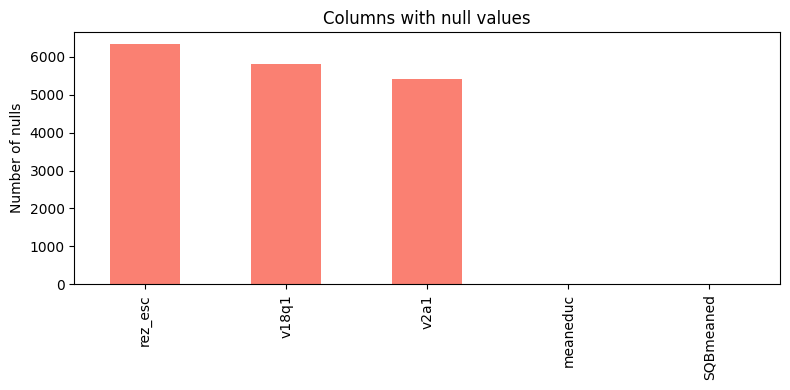

In [44]:
# Visualize nulls
plt.figure(figsize=(8,4))
nulls.plot(kind='bar', color='salmon')
plt.title("Columns with null values")
plt.ylabel("Number of nulls")
plt.tight_layout()
plt.show()

In [45]:
# Fill nulls with 0 (missing = no tablet, no rent, no school delay)
X_train['v2a1']    = X_train['v2a1'].fillna(0)
X_train['v18q1']   = X_train['v18q1'].fillna(0)
X_train['rez_esc'] = X_train['rez_esc'].fillna(0)
X_test['v2a1']     = X_test['v2a1'].fillna(0)
X_test['v18q1']    = X_test['v18q1'].fillna(0)
X_test['rez_esc']  = X_test['rez_esc'].fillna(0)


# meaneduc: calculate mean on TRAIN only, apply to both
mean_educ = X_train['meaneduc'].mean()
X_train['meaneduc'] = X_train['meaneduc'].fillna(mean_educ)
X_test['meaneduc']  = X_test['meaneduc'].fillna(mean_educ)
X_train["SQBmeaned"] = X_train["SQBmeaned"].fillna(mean_educ**2)
X_test["SQBmeaned"] = X_test["SQBmeaned"].fillna(mean_educ**2)

## Categorical Variables

In [46]:
# Check categorical columns
cat_cols = X_train.select_dtypes(include='object').columns
print(f"Categorical columns: {cat_cols.tolist()}")

Categorical columns: ['dependency', 'edjefe', 'edjefa']


In [47]:
for col in cat_cols:
    print(f"\nColumn: {col}")
    print(X_train[col].value_counts())


Column: dependency
dependency
yes          1811
no           1413
.5           1136
2             581
1.5           545
.33333334     480
.66666669     382
8             297
3             196
.25           195
4             100
.75            91
.2             78
.40000001      63
1.3333334      63
2.5            42
1.25           18
.80000001      18
2.25           13
.71428573      12
5              12
1.75           11
.83333331      11
1.2            11
3.5             9
.2857143        9
1.6666666       8
.60000002       8
6               7
.16666667       7
Name: count, dtype: int64

Column: edjefe
edjefe
no     3017
6      1464
11      607
9       384
3       223
7       218
15      216
8       187
17      182
5       179
14      161
2       161
yes     107
16      101
4       100
12      100
10       91
13       63
21       38
18       16
20        7
19        5
Name: count, dtype: int64

Column: edjefa
edjefa
no     4962
6       750
11      321
9       201
8       177
7      

It does not make sense for `edjefe/a` to be treated as a categorical variable. Also, it doesn't make sense to have to different columns that have complementary information, so we can represent them in one. Some entries contain `"no"`. It is necessary to determine what this value represents, which will in this case means the head doesn't have any level of education, and completed with a `0`. And in the case of `"yes", we will imput the mean. 

In [48]:
# check that there are no observations where both, edjefe and edjefa are numerical values
edjefe_num = pd.to_numeric(X_train['edjefe'], errors='coerce')
edjefa_num = pd.to_numeric(X_train['edjefa'], errors='coerce')
both_num = edjefe_num.notnull() & edjefa_num.notnull()
print(f"\nObservations where both edjefe and edjefa are both numeric: {both_num.sum()} (should be 0)")


Observations where both edjefe and edjefa are both numeric: 0 (should be 0)


In [49]:
# check that there are no observations where none, edjefe and edjefa are numerical values
edjefe_num = pd.to_numeric(X_train['edjefe'], errors='coerce')
edjefa_num = pd.to_numeric(X_train['edjefa'], errors='coerce')
both_non_num = edjefe_num.isnull() & edjefa_num.isnull()
print(f"\nObservations where both edjefe and edjefa are both non-numeric: {both_non_num.sum()} (should be 0)")


Observations where both edjefe and edjefa are both non-numeric: 511 (should be 0)


In [50]:
def combine_education(row):
    edjefe_num = pd.to_numeric(row['edjefe'], errors='coerce')
    edjefa_num = pd.to_numeric(row['edjefa'], errors='coerce')

    if pd.notna(edjefe_num):
        return edjefe_num
    if pd.notna(edjefa_num):
        return edjefa_num

    if row['edjefe'] == 'yes' or row['edjefa'] == 'yes':
        return 'yes'
    if row['edjefe'] == 'no' or row['edjefa'] == 'no':
        return 'no'

    return np.nan

X_train['education_head'] = X_train.apply(combine_education, axis=1)
X_test['education_head']  = X_test.apply(combine_education, axis=1)

X_train['education_head'] = X_train['education_head'].replace({'no': 0, 'yes': np.nan})
X_test['education_head']  = X_test['education_head'].replace({'no': 0, 'yes': np.nan})

mode_education = X_train['education_head'].mode(dropna=True)[0]
X_train['education_head'] = X_train['education_head'].fillna(mode_education)
X_test['education_head']  = X_test['education_head'].fillna(mode_education)

#check if it worked (see value counts)
print("\nEducation head value counts:")
print(X_train['education_head'].value_counts(dropna=False))


Education head value counts:
education_head
6.0     2373
11.0     928
9.0      585
7.0      376
15.0     364
8.0      364
0.0      352
3.0      348
5.0      314
14.0     260
17.0     243
2.0      221
4.0      213
16.0     195
10.0     161
12.0     146
13.0     104
21.0      43
18.0      19
19.0       9
20.0       9
Name: count, dtype: int64


/var/folders/86/zd3c8_k52zn4yd5znl4pwwdm0000gn/T/ipykernel_33968/3688888788.py:20: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_train['education_head'] = X_train['education_head'].replace({'no': 0, 'yes': np.nan})
/var/folders/86/zd3c8_k52zn4yd5znl4pwwdm0000gn/T/ipykernel_33968/3688888788.py:21: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_test['education_head']  = X_test['education_head'].replace({'no': 0, 'yes': np.nan})


In [51]:
# which are the highest numbers of dependency  nunique
print("\nTop 10 highest dependency values:")
print(pd.to_numeric(X_train['dependency'], errors='coerce').dropna().sort_values(ascending=False).unique()[:10])



Top 10 highest dependency values:
[8.   6.   5.   4.   3.5  3.   2.5  2.25 2.   1.75]


We see that none of them suprass 10, so as it is a ratio we assume that it's a mistake and they were meant to be divided by 10

In [52]:
def clean_ratio_dependency(value):
    if pd.isna(value):
        return np.nan
    if value == 'no':
        return 0
    if value == 'yes':
        return 1
    try:
        num = float(value)
        if num > 1:
            return num / 10
        return num
    except ValueError:
        return np.nan

X_train['dependency'] = X_train['dependency'].apply(clean_ratio_dependency)
X_test['dependency'] = X_test['dependency'].apply(clean_ratio_dependency)

print("\nDependency value counts:")
print(X_train['dependency'].value_counts(dropna=False).sort_index())




Dependency value counts:
dependency
0.000000    1413
0.120000      11
0.125000      18
0.133333      63
0.150000     545
0.166667       8
0.166667       7
0.175000      11
0.200000     659
0.225000      13
0.250000     237
0.285714       9
0.300000     196
0.333333     480
0.350000       9
0.400000     100
0.400000      63
0.500000    1148
0.600000       7
0.600000       8
0.666667     382
0.714286      12
0.750000      91
0.800000     297
0.800000      18
0.833333      11
1.000000    1811
Name: count, dtype: int64


In [53]:
# These 3 columns look numeric but are stored as strings, so we need to convert them to numeric
transformation = {'yes': 1, 'no': 0}
for col in ['dependency', 'edjefe', 'edjefa']:
    X_train[col] = pd.to_numeric(X_train[col].replace(transformation), errors='coerce').fillna(0)
    X_test[col]  = pd.to_numeric(X_test[col].replace(transformation), errors='coerce').fillna(0)

# Check no categorical columns remain
cat_cols = X_train.select_dtypes(include='object').columns
print(f"Remaining categorical columns: {cat_cols.tolist()}")  # should be []

Remaining categorical columns: []


No additional categorical encoding was required because the dataset is already largely preprocessed, with most categorical variables provided as binary dummy indicators, allowing them to be used directly in the models.

## Balance of classes

In [54]:
# Check target distribution (only household heads, 1 per household)
target_counts = train_df[train_df['parentesco1'] == 1]['Target'].value_counts().sort_index()
print(target_counts)
print("\nPercentage:")
print((target_counts / target_counts.sum() * 100).round(1))

Target
1.0     178
2.0     353
3.0     284
4.0    1563
Name: count, dtype: int64

Percentage:
Target
1.0     7.5
2.0    14.8
3.0    11.9
4.0    65.7
Name: count, dtype: float64


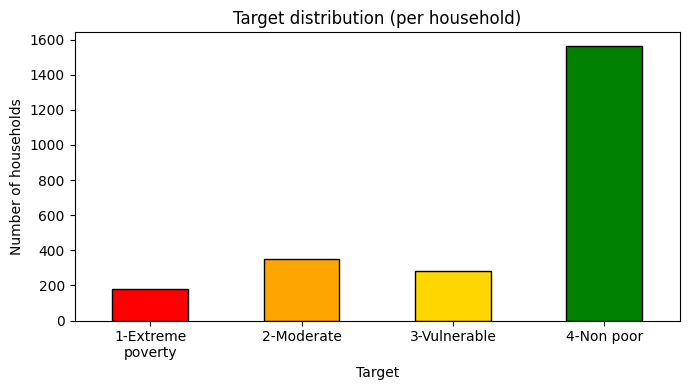

In [55]:
plt.figure(figsize=(7,4))
target_counts.plot(kind='bar', color=['red','orange','gold','green'], edgecolor='black')
plt.xticks([0,1,2,3], ['1-Extreme\npoverty','2-Moderate','3-Vulnerable','4-Non poor'], rotation=0)
plt.title("Target distribution (per household)")
plt.ylabel("Number of households")
plt.tight_layout()
plt.show()

## Outliers

In [56]:
# Separate continuous columns from binary (0/1) columns
binary_cols     = [col for col in X_train.columns if X_train[col].nunique() == 2]
continuous_cols = [col for col in X_train.columns if col not in binary_cols]

print(f"Continuous columns: {len(continuous_cols)}")
print(f"Binary columns:     {len(binary_cols)}")

Continuous columns: 40
Binary columns:     101


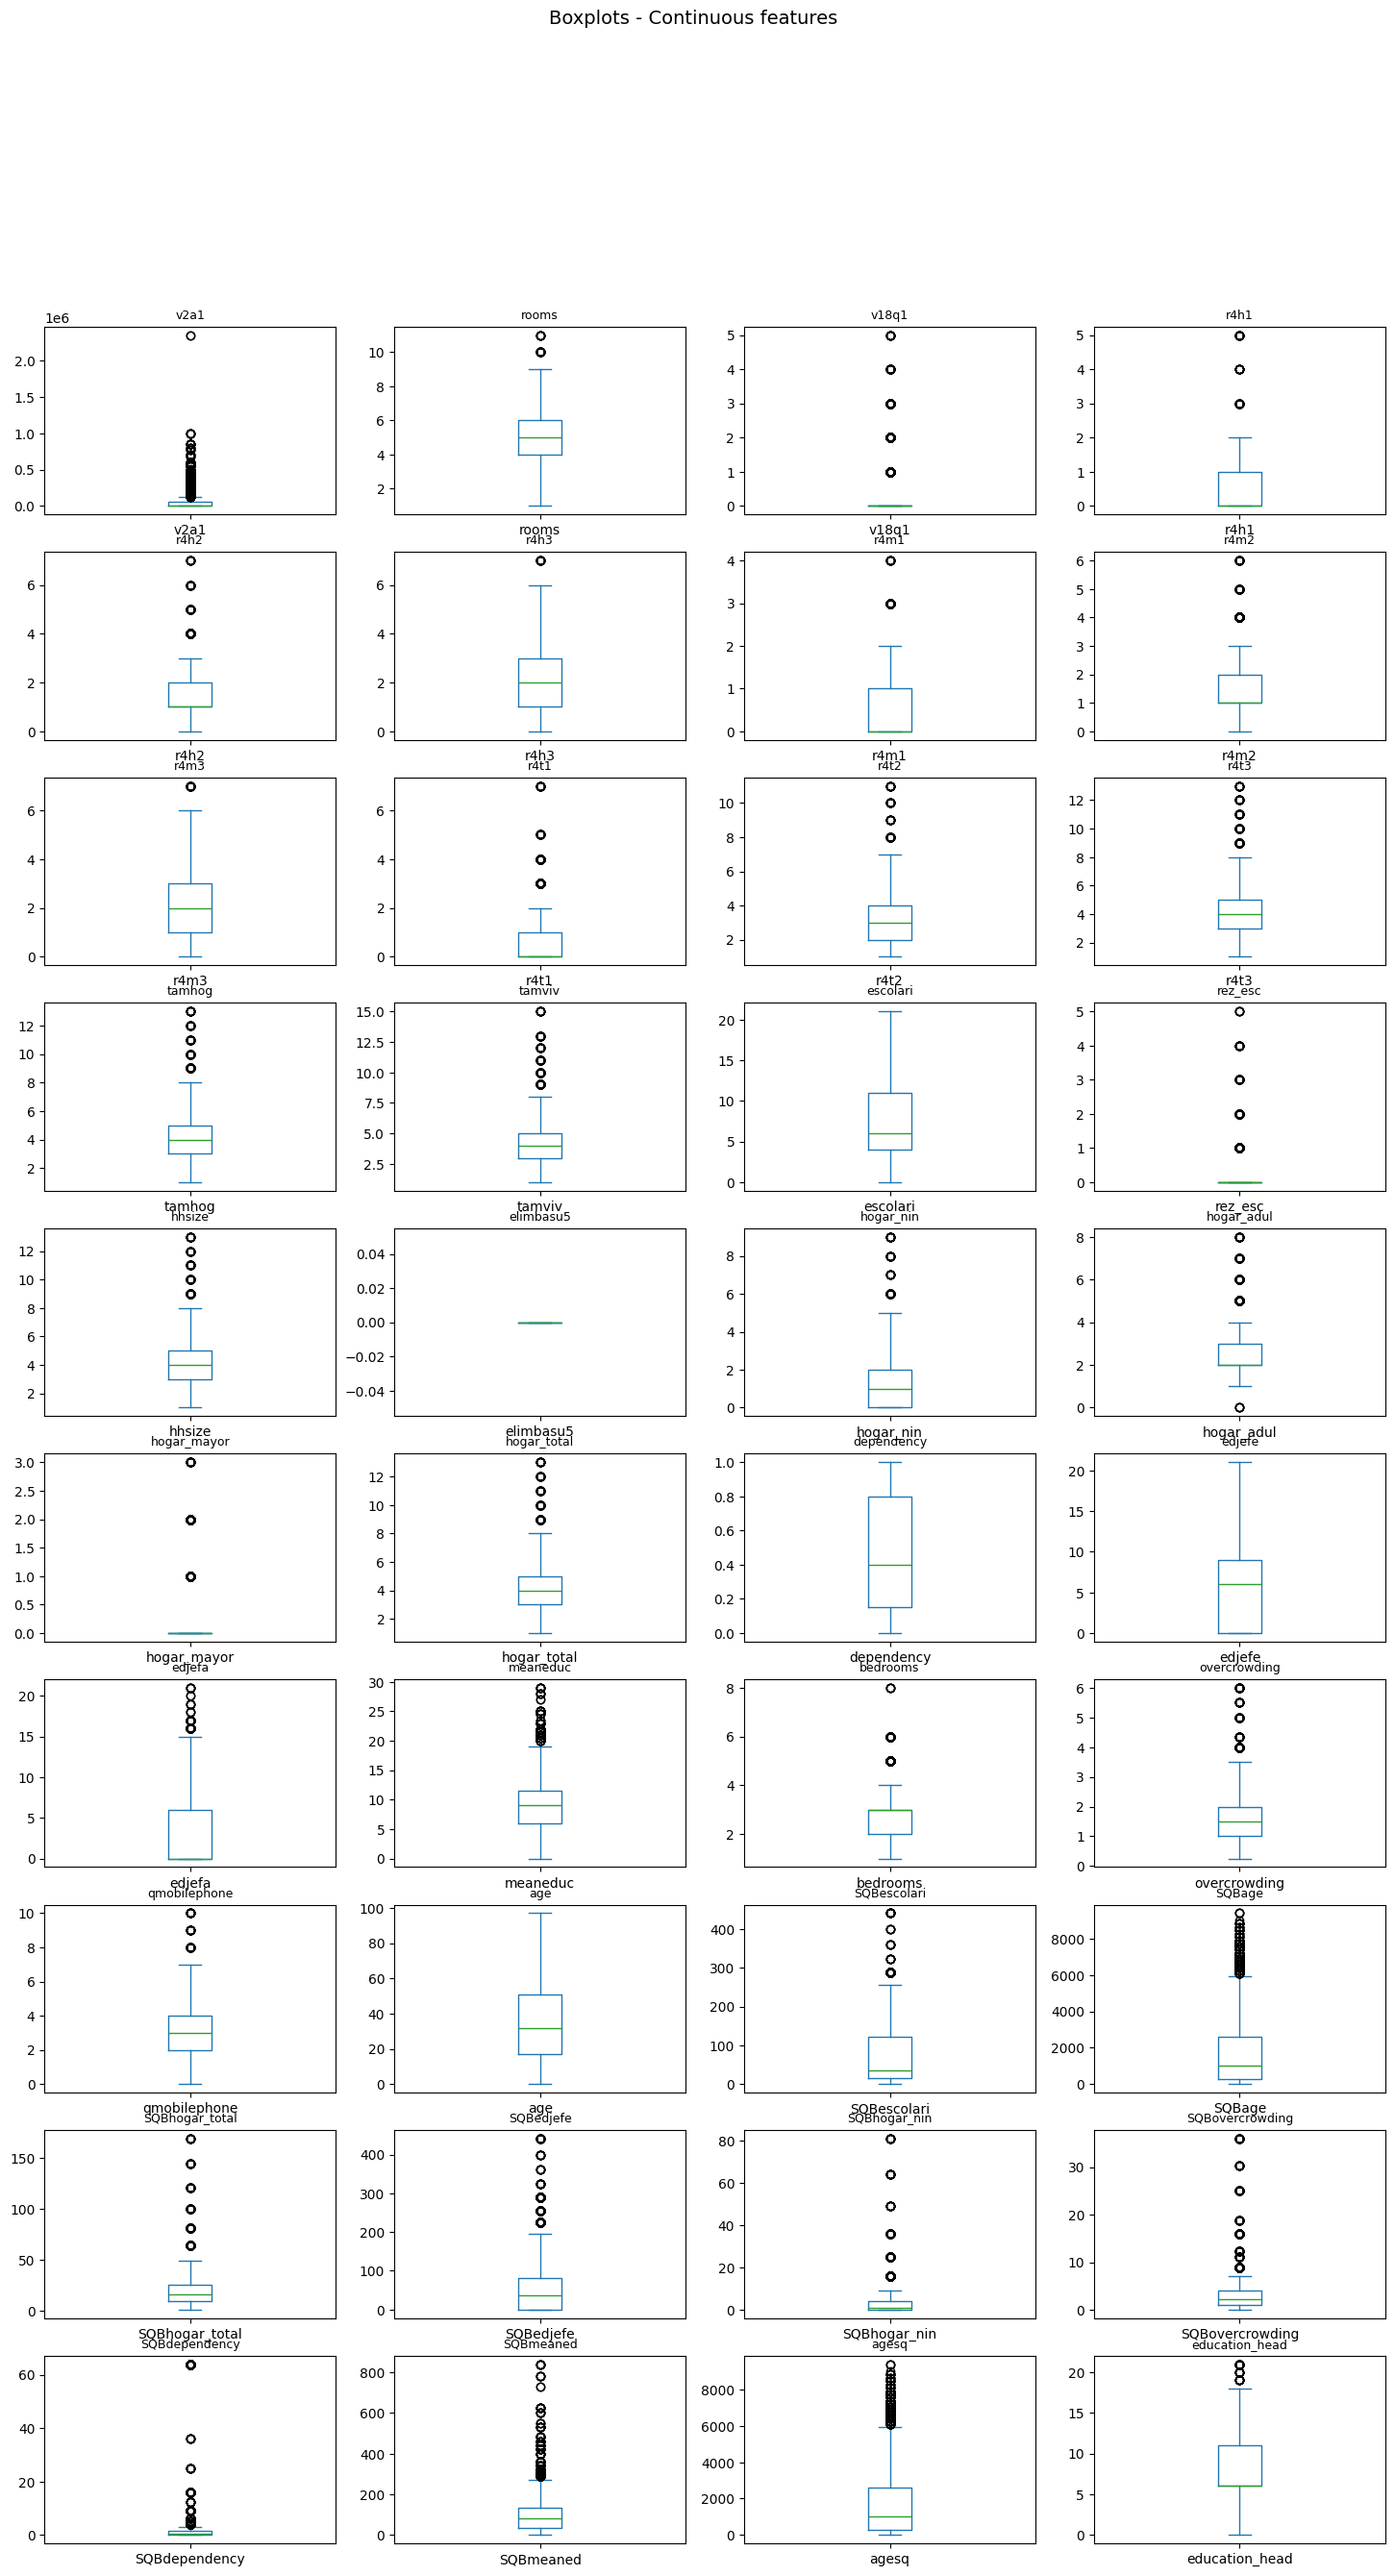

In [57]:
 # Boxplots of continuous columns
n_cols = 4
n_rows = (len(continuous_cols) // n_cols) + 1

plt.figure(figsize=(18, n_rows * 3))
for i, col in enumerate(continuous_cols):
    plt.subplot(n_rows, n_cols, i + 1)
    X_train[col].plot(kind='box')
    plt.title(col, fontsize=9)
plt.suptitle("Boxplots - Continuous features", fontsize=14)
plt.show()

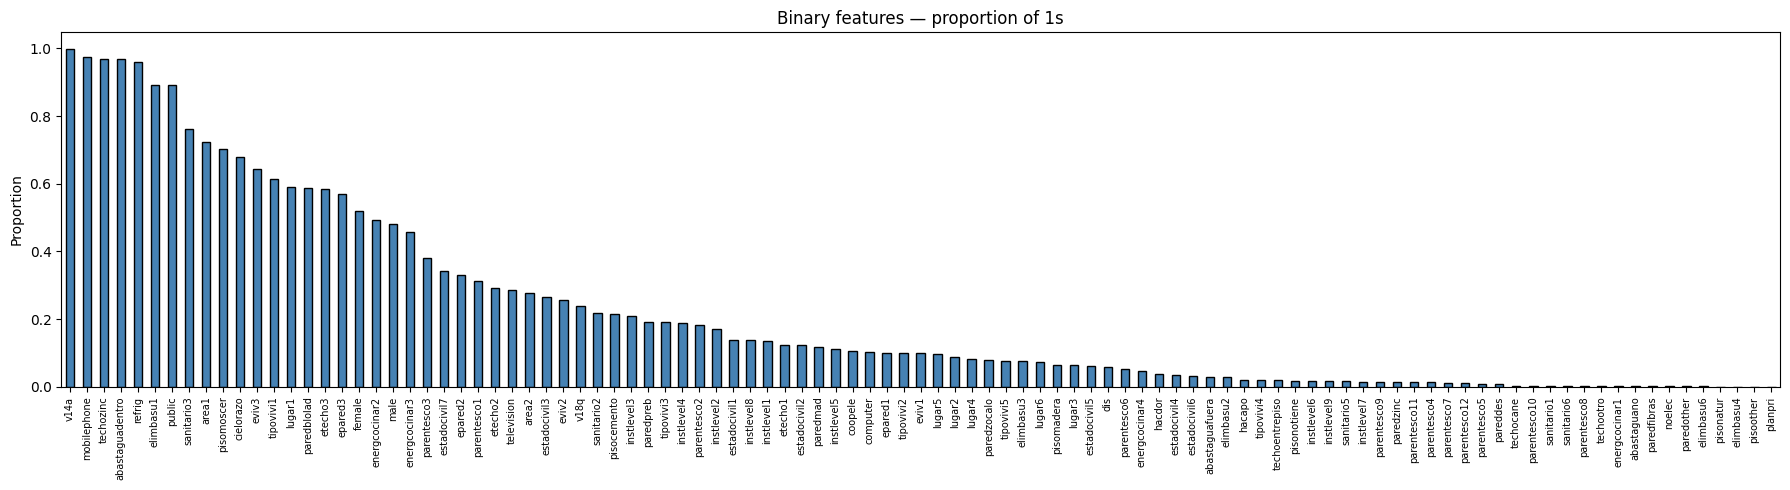

In [58]:
 # Binary columns → bar chart showing proportion of 1s
binary_means = X_train[binary_cols].mean().sort_values(ascending=False)

plt.figure(figsize=(18, 5))
binary_means.plot(kind='bar', color='steelblue', edgecolor='black')
plt.title("Binary features — proportion of 1s")
plt.ylabel("Proportion")
plt.xticks(rotation=90, fontsize=7)
plt.tight_layout()
plt.show()


# Feature Engineering

In [59]:
# Applied to X_train and X_test directly (after cleaning, before feature selection)

asset_cols = ['refrig', 'computer', 'television', 'mobilephone', 'v18q']

# Concatenate for vectorized operations
X_all = pd.concat([X_train, X_test], axis=0, ignore_index=True)

# Housing vulnerability score: combines housing type columns into one risk score
X_all['housing_vulnerability'] = (
    X_all['tipovivi4'] * 3 +   # precarious = highest risk
    X_all['tipovivi5'] * 2 +   # free/other = moderate risk
    X_all['tipovivi2'] * 1 +   # still paying = some burden
    X_all['tipovivi1'] * -1    # own = lowest risk
)
# For tipovivi3 (rent), we keep it as 0

# Asset count: total number of assets owned by the household
X_all['asset_count'] = X_all[asset_cols].sum(axis=1)

# Rent per person: financial burden indicator
X_all['rent_per_person'] = X_all['v2a1'] / X_all['hhsize'].replace(0, 1)
new_features = ['housing_vulnerability', 'asset_count', 'rent_per_person']

# Split back to X_train and X_test
X_train[new_features] = X_all.loc[:len(X_train)-1, new_features].values
X_test[new_features] = X_all.loc[len(X_train):, new_features].values

# Check the new features
print("New features added:")
print(X_train[new_features].head())


New features added:
   housing_vulnerability  asset_count  rent_per_person
0                    0.0          2.0         190000.0
1                    0.0          3.0         135000.0
2                   -1.0          1.0              0.0
7                    0.0          2.0          32500.0
8                    0.0          2.0          32500.0


# Feature Selection

ABSOLUTE CORRELATION: PEARSON

In [60]:
# Use absolute correlation to avoid negative values canceling out positive ones, and sort by correlation score.
X_train_fs = X_train.copy()
X_test_fs = X_test.copy()
corr_values = X_train_fs.corrwith(y_train).abs()

corr_df = pd.DataFrame({
    "feature": X_train_fs.columns,
    "corr_score": corr_values
}).sort_values(by="corr_score", ascending=False)

corr_df.head(15)

/Users/mireiacalvinosaez/anaconda3/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/mireiacalvinosaez/anaconda3/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,feature,corr_score
meaneduc,meaneduc,0.338560
hogar_nin,hogar_nin,0.334791
r4t1,r4t1,0.328280
education_head,education_head,0.322192
SQBhogar_nin,SQBhogar_nin,0.315510
cielorazo,cielorazo,0.312830
asset_count,asset_count,0.311897
epared3,epared3,0.307233
escolari,escolari,0.305914
eviv3,eviv3,0.300525


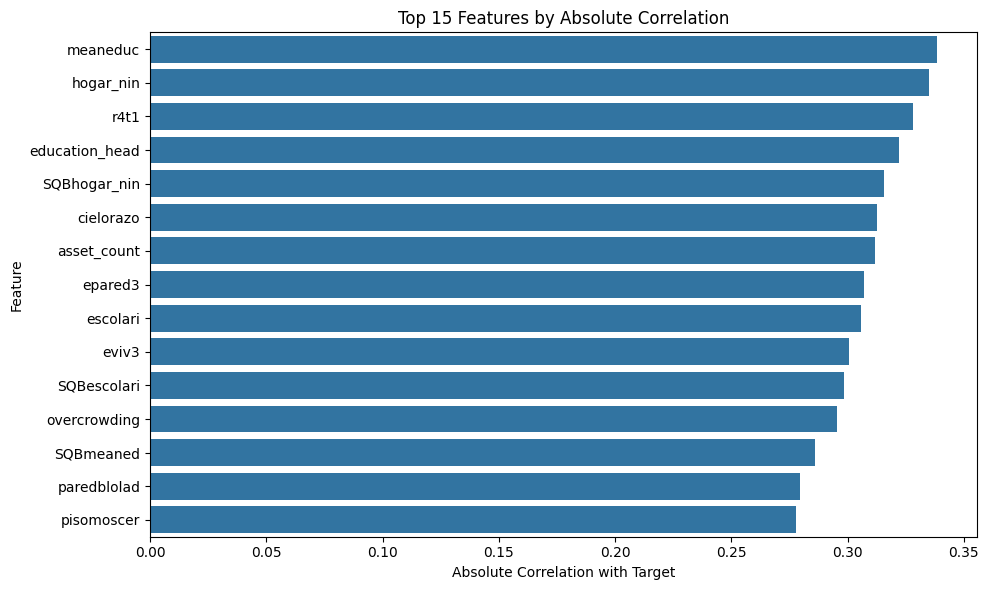

In [61]:
# Plot Absolute Correlation results

plt.figure(figsize=(10, 6))
sns.barplot(
    data=corr_df.head(15),
    x="corr_score",
    y="feature"
)

plt.title("Top 15 Features by Absolute Correlation")
plt.xlabel("Absolute Correlation with Target")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

MUTUAL INFORMATION (MI)

In [62]:
mi_values = mutual_info_classif(
    X_train_fs,
    y_train,
    random_state=42
)

mi_df = pd.DataFrame({
    "feature": X_train_fs.columns,
    "mi_score": mi_values
}).sort_values(by="mi_score", ascending=False)

mi_df.head(15)

,feature,mi_score
101,meaneduc,0.168428
138,SQBmeaned,0.167776
137,SQBdependency,0.111182
98,dependency,0.103936
143,rent_per_person,0.101708
140,education_head,0.085724
136,SQBovercrowding,0.076312
131,SQBescolari,0.073208
112,overcrowding,0.071224
135,SQBhogar_nin,0.071093


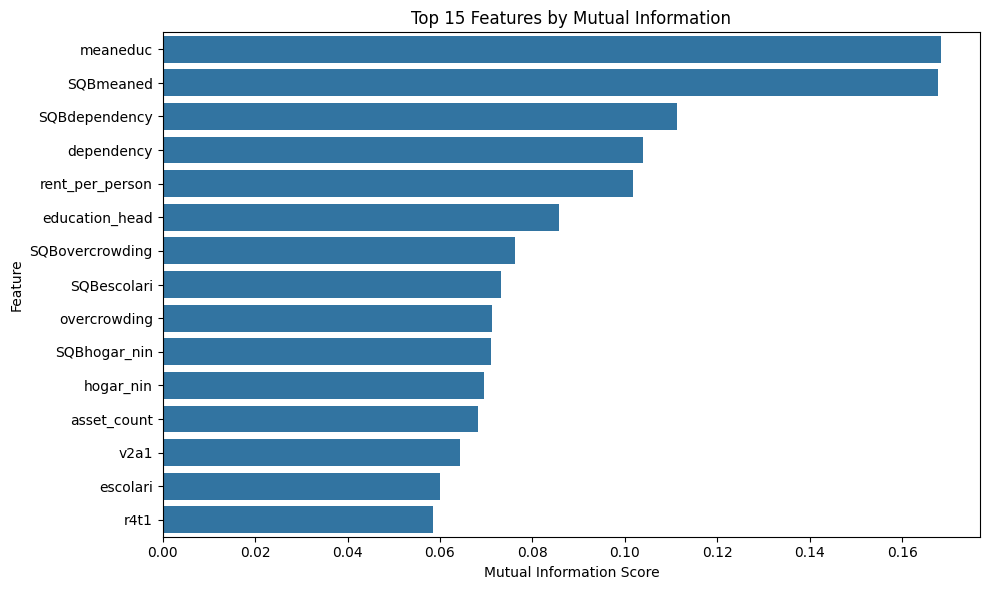

In [63]:
# Plot Mutual Information results

plt.figure(figsize=(10, 6))
sns.barplot(
    data=mi_df.head(15),
    x="mi_score",
    y="feature"
)

plt.title("Top 15 Features by Mutual Information")
plt.xlabel("Mutual Information Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

RANDOM FOREST FEATURE IMPORTANCE (RF)

In [64]:
rf_fs = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_fs.fit(X_train_fs, y_train)

rf_df = pd.DataFrame({
    "feature": X_train_fs.columns,
    "rf_importance": rf_fs.feature_importances_
}).sort_values(by="rf_importance", ascending=False)

rf_df.head(15)

,feature,rf_importance
138,SQBmeaned,0.042983
101,meaneduc,0.042942
140,education_head,0.031392
137,SQBdependency,0.026495
112,overcrowding,0.024181
136,SQBovercrowding,0.023855
121,qmobilephone,0.022580
134,SQBedjefe,0.021711
99,edjefe,0.020989
2,rooms,0.020434


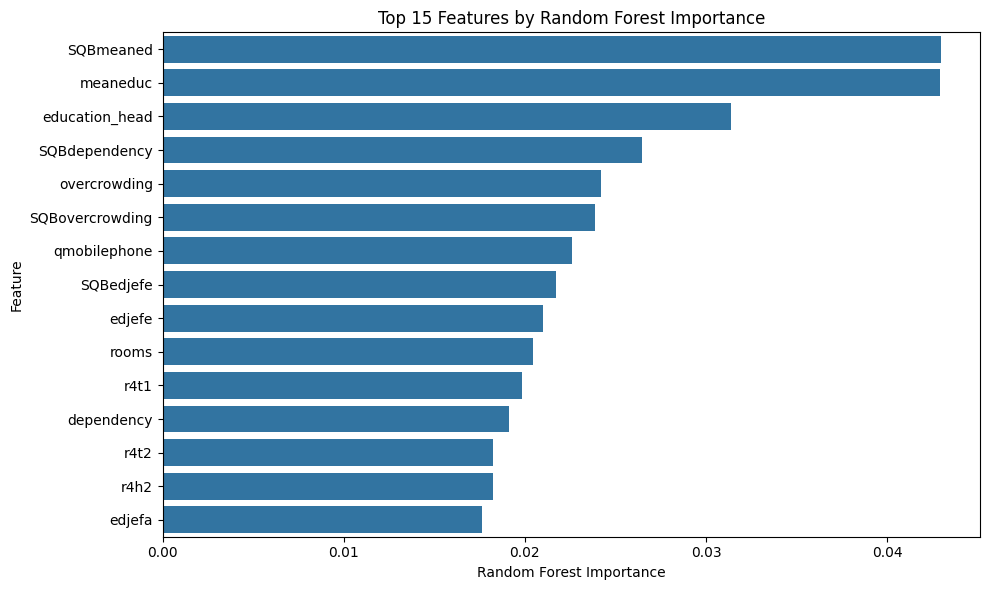

In [65]:
# Plot Random Forest results

plt.figure(figsize=(10, 6))
sns.barplot(
    data=rf_df.head(15),
    x="rf_importance",
    y="feature"
)

plt.title("Top 15 Features by Random Forest Importance")
plt.xlabel("Random Forest Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

COMBINATION OF FEATURE SELECTION METHODS

In [66]:
combined_fs = corr_df.merge(
    mi_df,
    on="feature"
).merge(
    rf_df,
    on="feature"
)

combined_fs["corr_rank"] = combined_fs["corr_score"].rank(ascending=False)
combined_fs["mi_rank"] = combined_fs["mi_score"].rank(ascending=False)
combined_fs["rf_rank"] = combined_fs["rf_importance"].rank(ascending=False)

combined_fs["average_rank"] = combined_fs[
    ["corr_rank", "mi_rank", "rf_rank"]
].mean(axis=1)

combined_fs = combined_fs.sort_values(by="average_rank")

combined_fs.head(25)

,feature,corr_score,mi_score,rf_importance,corr_rank,mi_rank,rf_rank,average_rank
0,meaneduc,0.338560,0.168428,0.042942,1.0,1.0,2.0,1.333333
3,education_head,0.322192,0.085724,0.031392,4.0,6.0,3.0,4.333333
12,SQBmeaned,0.285969,0.167776,0.042983,13.0,2.0,1.0,5.333333
11,overcrowding,0.295423,0.071224,0.024181,12.0,9.0,5.0,8.666667
2,r4t1,0.328280,0.058441,0.019837,3.0,15.0,11.0,9.666667
1,hogar_nin,0.334791,0.069438,0.016307,2.0,11.0,17.0,10.000000
16,SQBovercrowding,0.267120,0.076312,0.023855,17.0,7.0,6.0,10.000000
4,SQBhogar_nin,0.315510,0.071093,0.016526,5.0,10.0,16.0,10.333333
6,asset_count,0.311897,0.068222,0.015667,7.0,12.0,20.0,13.000000
19,SQBedjefe,0.248174,0.055526,0.021711,20.0,16.0,8.0,14.666667


REMOVING THE REDUNDANT SQB FEATURES

In [67]:
# If both a squared feature and its original version appear we will only keep the one with the better average rank as they represent the same

combined_fs_clean = combined_fs.copy()

features_to_drop = []

for feature in combined_fs_clean["feature"]:
    
    if feature.startswith("SQB"):
        original_feature = feature.replace("SQB", "", 1)
        
        if original_feature in combined_fs_clean["feature"].values:
            
            sqb_rank = combined_fs_clean.loc[
                combined_fs_clean["feature"] == feature,
                "average_rank"
            ].values[0]
            
            original_rank = combined_fs_clean.loc[
                combined_fs_clean["feature"] == original_feature,
                "average_rank"
            ].values[0]
            
            if sqb_rank < original_rank:
                features_to_drop.append(original_feature)
            else:
                features_to_drop.append(feature)

# Manual removes

features_to_drop.append("SQBmeaned")

features_to_drop = list(set(features_to_drop))

print("Redundant SQB/original features removed:")
print(features_to_drop)


combined_fs_clean = combined_fs_clean[
    combined_fs_clean["feature"].isin(features_to_drop) == False
].sort_values(by="average_rank")

combined_fs_clean.head(30)

Redundant SQB/original features removed:
['SQBhogar_total', 'SQBhogar_nin', 'escolari', 'dependency', 'edjefe', 'SQBage', 'SQBmeaned', 'SQBovercrowding']


,feature,corr_score,mi_score,rf_importance,corr_rank,mi_rank,rf_rank,average_rank
0,meaneduc,0.338560,0.168428,0.042942,1.0,1.0,2.0,1.333333
3,education_head,0.322192,0.085724,0.031392,4.0,6.0,3.0,4.333333
11,overcrowding,0.295423,0.071224,0.024181,12.0,9.0,5.0,8.666667
2,r4t1,0.328280,0.058441,0.019837,3.0,15.0,11.0,9.666667
1,hogar_nin,0.334791,0.069438,0.016307,2.0,11.0,17.0,10.000000
6,asset_count,0.311897,0.068222,0.015667,7.0,12.0,20.0,13.000000
19,SQBedjefe,0.248174,0.055526,0.021711,20.0,16.0,8.0,14.666667
10,SQBescolari,0.298421,0.073208,0.010748,11.0,8.0,38.0,19.000000
22,rooms,0.223068,0.037870,0.020434,23.0,25.0,10.0,19.333333
7,epared3,0.307233,0.045594,0.011392,8.0,20.0,31.0,19.666667


CHOOSING NUMBER OF FEATURES

In [68]:
# Logistic Regression used as baseline to decide number of features
results = []

for k in range(10, 60, 1):
    
    features_k = combined_fs_clean.head(k)["feature"].tolist()
    
    X_train_k = X_train_fs[features_k]
    
    
    scaler = StandardScaler()
    X_train_k_scaled = scaler.fit_transform(X_train_k)
    
    
    model = LogisticRegression(
        max_iter=5000,
        class_weight="balanced",
        random_state=42
    )
    
    cv_score = cross_val_score(
        model, X_train_k_scaled, y_train, cv=5, scoring="accuracy"
    ).mean()
    
    results.append({"number_features": k, "cv_accuracy": cv_score})

feature_number_results = pd.DataFrame(results)

feature_number_results

,number_features,cv_accuracy
0,10,0.529162
1,11,0.533881
2,12,0.546076
3,13,0.548957
4,14,0.551709
5,15,0.548693
6,16,0.551578
7,17,0.555118
8,18,0.551315
9,19,0.547119


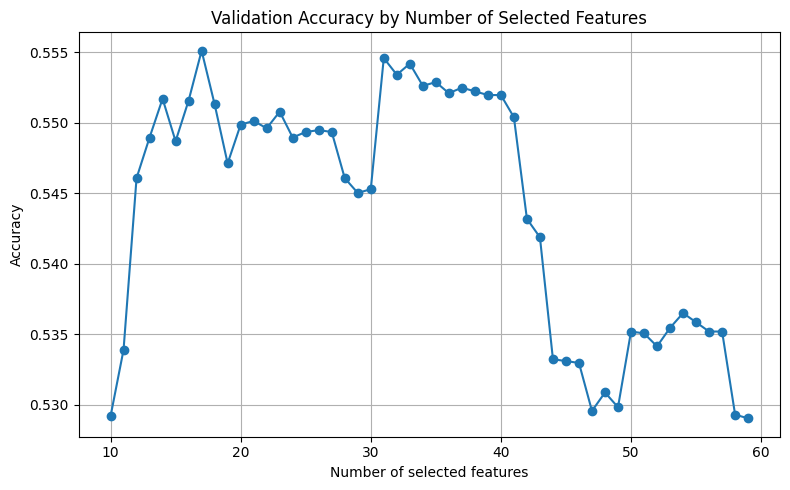

In [69]:
plt.figure(figsize=(8, 5))
plt.plot(
    feature_number_results["number_features"],
    feature_number_results["cv_accuracy"],
    marker="o"
)

plt.title("Validation Accuracy by Number of Selected Features")
plt.xlabel("Number of selected features")
plt.ylabel("Accuracy")
plt.grid(True)
plt.tight_layout()
plt.show()

In [70]:
best_k = feature_number_results.sort_values(
    by="cv_accuracy",
    ascending=False
).iloc[0]["number_features"]

best_k = int(best_k)

print("Best number of features:", best_k)

Best number of features: 17


FINAL SELECTED FEATURES

In [71]:
selected_features = combined_fs_clean.head(best_k)["feature"].tolist()

print("Number of selected features:", len(selected_features))
print(selected_features)

Number of selected features: 17
['meaneduc', 'education_head', 'overcrowding', 'r4t1', 'hogar_nin', 'asset_count', 'SQBedjefe', 'SQBescolari', 'rooms', 'epared3', 'cielorazo', 'qmobilephone', 'rent_per_person', 'v2a1', 'SQBdependency', 'eviv3', 'paredblolad']


FINAL DATASET FOR MODELING

In [72]:
X_train_selected = X_train_fs[selected_features].copy()
X_test_selected = X_test_fs[selected_features].copy()

print("X_train_selected shape:", X_train_selected.shape)
print("X_test_selected shape:", X_test_selected.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train_selected shape: (7627, 17)
X_test_selected shape: (1907, 17)
y_train shape: (7627,)
y_test shape: (1907,)


FEATURE SELECTION SUMMARY

In [73]:
final_feature_selection_summary = combined_fs_clean[
    combined_fs_clean["feature"].isin(selected_features)
].sort_values(by="average_rank")

final_feature_selection_summary

,feature,corr_score,mi_score,rf_importance,corr_rank,mi_rank,rf_rank,average_rank
0,meaneduc,0.338560,0.168428,0.042942,1.0,1.0,2.0,1.333333
3,education_head,0.322192,0.085724,0.031392,4.0,6.0,3.0,4.333333
11,overcrowding,0.295423,0.071224,0.024181,12.0,9.0,5.0,8.666667
2,r4t1,0.328280,0.058441,0.019837,3.0,15.0,11.0,9.666667
1,hogar_nin,0.334791,0.069438,0.016307,2.0,11.0,17.0,10.000000
6,asset_count,0.311897,0.068222,0.015667,7.0,12.0,20.0,13.000000
19,SQBedjefe,0.248174,0.055526,0.021711,20.0,16.0,8.0,14.666667
10,SQBescolari,0.298421,0.073208,0.010748,11.0,8.0,38.0,19.000000
22,rooms,0.223068,0.037870,0.020434,23.0,25.0,10.0,19.333333
7,epared3,0.307233,0.045594,0.011392,8.0,20.0,31.0,19.666667


## Modelling

We evaluate four flat multiclass baselines first, then a hierarchical pipeline designed to address the severe class imbalance (63% class 4). All models are evaluated on household heads only (one row per household) to avoid inflating metrics with duplicated household-level labels. Macro F1 is used as the primary metric since accuracy is dominated by class 4.

## Multiclass Classification (Poverty Levels 1–4)

We first attempt to classify all four poverty levels directly. Given the severe class imbalance (≈63% class 4), we test two imbalance-handling strategies before concluding on whether the task is learnable at this granularity:

1. **Class weighting** — penalise misclassification of minority classes
2. **SMOTE** — synthetic oversampling of minority classes

Four algorithms are evaluated under both strategies: Logistic Regression, Random Forest, AdaBoost, and KNN. Macro F1 is the primary metric, as accuracy is dominated by the non-poor majority class.

### Class Weighting

All four models are tuned via cross-validated grid search with class weights included as a hyperparameter.

In [74]:
classes = np.array([1, 2, 3, 4])
bal_weights = compute_class_weight('balanced', classes=classes, y=y_train)
computed_weights = dict(zip(classes, bal_weights))
aggressive_weights = {k: v * (2.5 if k in [1, 2, 3] else 1.0)
                      for k, v in computed_weights.items()}
print("Aggressive weights:", aggressive_weights)

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

Aggressive weights: {np.int64(1): np.float64(7.7763050570962475), np.int64(2): np.float64(3.844254032258064), np.int64(3): np.float64(4.869126659856997), np.int64(4): np.float64(0.39765380604796663)}


## Flat Baselines
Before the hierarchical approach, we run four standard classifiers on the full 4-class problem to establish a baseline and justify the need for a more sophisticated pipeline.

In [75]:
from sklearn.pipeline import make_pipeline

# Logistic Regression
pipe_lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, random_state=42))
grid_lr = GridSearchCV(
    pipe_lr,
    param_grid={
        "logisticregression__C":            [0.01, 0.1, 1, 10],
        "logisticregression__solver":       ["lbfgs", "saga"],
        "logisticregression__class_weight": ["balanced", aggressive_weights],
    },
    cv=cv5, scoring="f1_macro", n_jobs=-1, refit=True,
)
grid_lr.fit(X_train_selected, y_train)
preds_lr = grid_lr.predict(X_test_selected)

# Random Forest
grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid={
        "n_estimators":     [200, 400],
        "max_depth":        [None, 10, 20],
        "min_samples_leaf": [1, 3],
        "class_weight":     ["balanced", "balanced_subsample", aggressive_weights],
    },
    cv=cv5, scoring="f1_macro", n_jobs=-1, refit=True,
)
grid_rf.fit(X_train_selected, y_train)
preds_rf = grid_rf.predict(X_test_selected)

# AdaBoost
grid_ada = GridSearchCV(
    AdaBoostClassifier(
        estimator=DecisionTreeClassifier(class_weight="balanced"),
        random_state=42,
    ),
    param_grid={
        "n_estimators":         [100, 200, 400],
        "learning_rate":        [0.5, 1.0, 1.5],
        "estimator__max_depth": [1, 2, 3],
    },
    cv=cv5, scoring="f1_macro", n_jobs=-1, refit=True,
)
grid_ada.fit(X_train_selected, y_train)
preds_ada = grid_ada.predict(X_test_selected)

# K-Nearest Neighbors
pipe_knn = make_pipeline(StandardScaler(), KNeighborsClassifier())
grid_knn = GridSearchCV(
    pipe_knn,
    param_grid={
        "kneighborsclassifier__n_neighbors": [3, 5, 9, 15, 21],
        "kneighborsclassifier__weights":     ["uniform", "distance"],
        "kneighborsclassifier__metric":      ["euclidean", "manhattan"],
    },
    cv=cv5, scoring="f1_macro", n_jobs=-1, refit=True,
)
grid_knn.fit(X_train_selected, y_train)
preds_knn = grid_knn.predict(X_test_selected)

/Users/mireiacalvinosaez/anaconda3/lib/python3.11/site-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
45 fits failed out of a total of 135.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
45 fits failed with the following error:
Traceback (most recent call last):
  File "/Users/mireiacalvinosaez/anaconda3/lib/python3.11/site-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/Users/mireiacalvinosaez/anaconda3/lib/python3.11/site-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/mireiacalvinosaez/anaconda3/lib/python3.

### Summary

In [76]:

baseline_results = {
    "Logistic Regression": {"preds": preds_lr, "best_params": grid_lr.best_params_},
    "Random Forest":       {"preds": preds_rf, "best_params": grid_rf.best_params_},
    "AdaBoost":            {"preds": preds_ada, "best_params": grid_ada.best_params_},
    "KNN":                 {"preds": preds_knn, "best_params": grid_knn.best_params_},
}

summary_baseline = pd.DataFrame([
    {
        "Model":      name,
        "Macro F1":   round(f1_score(y_test, v["preds"], average="macro"), 4),
        "Accuracy":   round(accuracy_score(y_test, v["preds"]), 4),
        "Best Params": v["best_params"],
    }
    for name, v in baseline_results.items()
]).sort_values("Macro F1", ascending=False).reset_index(drop=True)

print(summary_baseline.to_string(index=False))

              Model  Macro F1  Accuracy                                                                                                                        Best Params
Logistic Regression    0.4231    0.5621                 {'logisticregression__C': 1, 'logisticregression__class_weight': 'balanced', 'logisticregression__solver': 'saga'}
      Random Forest    0.3930    0.6602                                {'class_weight': 'balanced_subsample', 'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 200}
           AdaBoost    0.3779    0.4835                                                             {'estimator__max_depth': 3, 'learning_rate': 0.5, 'n_estimators': 100}
                KNN    0.3036    0.5496 {'kneighborsclassifier__metric': 'manhattan', 'kneighborsclassifier__n_neighbors': 3, 'kneighborsclassifier__weights': 'distance'}


## SMOTE

Using synthetic data to compensate for the class imbalance

In [81]:
smote_results = {}

# LR + SMOTE
pipe_lr_smote = ImbPipeline([
    ("smote", SMOTE(random_state=42)),
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=5000, class_weight="balanced", random_state=42)),
])
grid_lr_smote = GridSearchCV(
    pipe_lr_smote,
    param_grid={},
    cv=cv5, scoring="f1_macro", n_jobs=-1, refit=True,
)
grid_lr_smote.fit(X_train_selected, y_train)
smote_results["Logistic Regression + SMOTE"] = grid_lr_smote.predict(X_test_selected)

# RF + SMOTE
pipe_rf_smote = ImbPipeline([
    ("smote", SMOTE(random_state=42)),
    ("clf", RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1)),
])
grid_rf_smote = GridSearchCV(
    pipe_rf_smote,
    param_grid={},
    cv=cv5, scoring="f1_macro", n_jobs=-1, refit=True,
)
grid_rf_smote.fit(X_train_selected, y_train)
smote_results["Random Forest + SMOTE"] = grid_rf_smote.predict(X_test_selected)

# AdaBoost + SMOTE
pipe_ada_smote = ImbPipeline([
    ("smote", SMOTE(random_state=42)),
    ("clf", AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=2, class_weight="balanced"),
        n_estimators=200, random_state=42
    )),
])
grid_ada_smote = GridSearchCV(
    pipe_ada_smote,
    param_grid={},
    cv=cv5, scoring="f1_macro", n_jobs=-1, refit=True,
)
grid_ada_smote.fit(X_train_selected, y_train)
smote_results["AdaBoost + SMOTE"] = grid_ada_smote.predict(X_test_selected)

# KNN + SMOTE
pipe_knn_smote = ImbPipeline([
    ("smote", SMOTE(random_state=42)),
    ("scaler", StandardScaler()),
    ("clf", KNeighborsClassifier(n_neighbors=9, weights="distance")),
])
grid_knn_smote = GridSearchCV(
    pipe_knn_smote,
    param_grid={},
    cv=cv5, scoring="f1_macro", n_jobs=-1, refit=True,
)
grid_knn_smote.fit(X_train_selected, y_train)
smote_results["KNN + SMOTE"] = grid_knn_smote.predict(X_test_selected)

summary_smote = pd.DataFrame([
    {
        "Model":    name,
        "Macro F1": round(f1_score(y_test, preds, average="macro"), 4),
        "Accuracy": round(accuracy_score(y_test, preds), 4),
    }
    for name, preds in smote_results.items()
]).sort_values("Macro F1", ascending=False).reset_index(drop=True)

print(summary_smote.to_string(index=False))

                      Model  Macro F1  Accuracy
Logistic Regression + SMOTE    0.4033    0.5653
      Random Forest + SMOTE    0.4023    0.6177
           AdaBoost + SMOTE    0.3958    0.5695
                KNN + SMOTE    0.3194    0.4803


In [82]:
# Compare class-weighting vs SMOTE side by side
summary_weighted = summary_baseline[["Model", "Macro F1"]].copy()
summary_weighted.columns = ["Model", "Macro F1 (Weighted)"]
summary_weighted["Model"] = summary_weighted["Model"]

summary_smote_compare = summary_smote[["Model", "Macro F1"]].copy()
summary_smote_compare["Model"] = summary_smote_compare["Model"].str.replace(" + SMOTE", "")
summary_smote_compare.columns = ["Model", "Macro F1 (SMOTE)"]

comparison = summary_weighted.merge(summary_smote_compare, on="Model")
comparison["Δ (SMOTE - Weighted)"] = (comparison["Macro F1 (SMOTE)"] - comparison["Macro F1 (Weighted)"]).round(4)
print(comparison.to_string(index=False))

model_scores = {
    name: round(f1_score(y_test, v["preds"], average="macro"), 4)
    for name, v in baseline_results.items()
}
model_scores.update({
    name: round(f1_score(y_test, preds, average="macro"), 4)
    for name, preds in smote_results.items()
})
model_scores = dict(sorted(model_scores.items(), key=lambda item: item[1], reverse=True))

              Model  Macro F1 (Weighted)  Macro F1 (SMOTE)  Δ (SMOTE - Weighted)
Logistic Regression               0.4231            0.4033               -0.0198
      Random Forest               0.3930            0.4023                0.0093
           AdaBoost               0.3779            0.3958                0.0179
                KNN               0.3036            0.3194                0.0158



Classification Report — Logistic Regression (best overall):
                  precision    recall  f1-score   support

 Extreme Poverty       0.24      0.48      0.32       161
Moderate Poverty       0.39      0.29      0.33       318
      Vulnerable       0.22      0.40      0.28       222
        Non-Poor       0.86      0.67      0.76      1206

        accuracy                           0.56      1907
       macro avg       0.43      0.46      0.42      1907
    weighted avg       0.66      0.56      0.59      1907



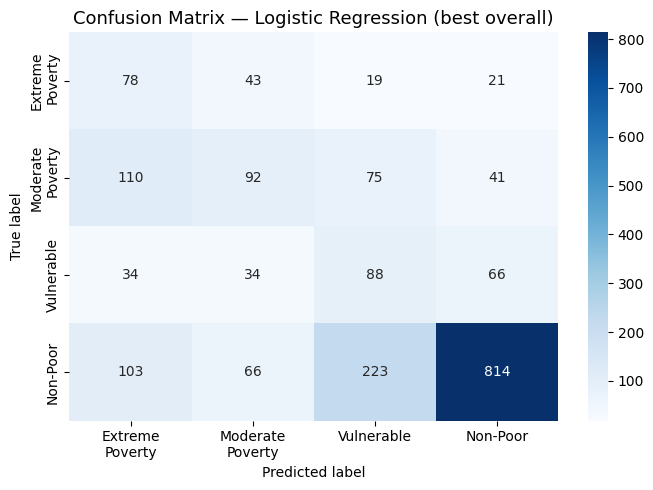

In [83]:
best_model_name = next(iter(model_scores))
if best_model_name in baseline_results:
    best_model_preds = baseline_results[best_model_name]["preds"]
else:
    best_model_preds = smote_results[best_model_name]

labels      = [1, 2, 3, 4]
label_names = ["Extreme\nPoverty", "Moderate\nPoverty", "Vulnerable", "Non-Poor"]

print(f"\nClassification Report — {best_model_name} (best overall):")
print(classification_report(y_test, best_model_preds,
      target_names=["Extreme Poverty","Moderate Poverty","Vulnerable","Non-Poor"]))

cm = confusion_matrix(y_test, best_model_preds, labels=labels)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=label_names, yticklabels=label_names)
plt.title(f"Confusion Matrix — {best_model_name} (best overall)", fontsize=13)
plt.ylabel("True label")
plt.xlabel("Predicted label")
plt.tight_layout()
plt.show()

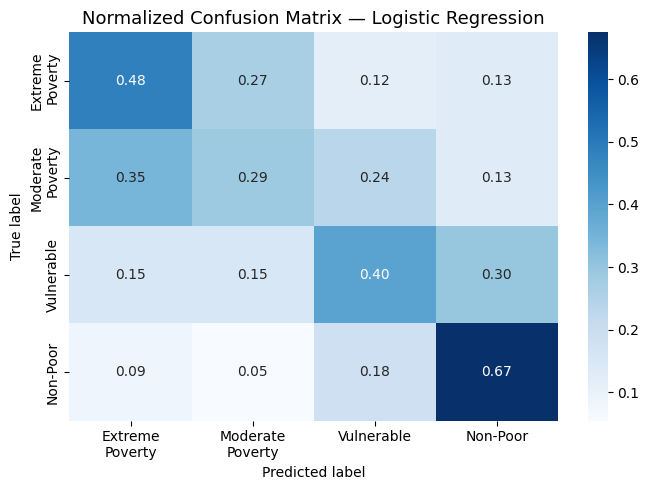

In [84]:
# confusion matrix normalized
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
plt.figure(figsize=(7, 5))
sns.heatmap(cm_normalized, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=label_names, yticklabels=label_names)
plt.title(f"Normalized Confusion Matrix — {best_model_name}", fontsize=13)
plt.ylabel("True label")
plt.xlabel("Predicted label")
plt.tight_layout()
plt.show()

## Why Does the Multiclass Model Fail? A Distributional Analysis

Neither class weighting nor SMOTE produced meaningful improvements in macro F1. Before concluding that the task is intractable, we investigate whether the failure is a modelling problem or a **data problem**, i.e., whether the features themselves carry enough signal to distinguish poverty levels 1, 2, and 3.

In [85]:
# Mean of top features by poverty class: are the classes actually different?
top_features_analysis = combined_fs_clean.head(12)["feature"].tolist()

X_analysis = X_train_selected.copy() if set(top_features_analysis).issubset(X_train_selected.columns) \
             else X_train_fs[top_features_analysis].copy()
X_analysis["Target"] = y_train.values

means_by_class = X_analysis.groupby("Target")[top_features_analysis].mean().T
means_by_class.columns = ["Extreme Poverty (1)", "Moderate Poverty (2)", "Vulnerable (3)", "Non-Poor (4)"]

print("Feature means by poverty class (top 12 features):")
print(means_by_class.round(3).to_string())

Feature means by poverty class (top 12 features):
                Extreme Poverty (1)  Moderate Poverty (2)  Vulnerable (3)  Non-Poor (4)
meaneduc                      6.707                 7.284           7.799        10.320
education_head                5.936                 6.119           6.331         9.259
overcrowding                  2.057                 1.967           1.751         1.426
r4t1                          1.667                 1.193           0.827         0.569
hogar_nin                     2.361                 2.031           1.695         1.072
asset_count                   2.051                 2.181           2.318         2.772
SQBedjefe                    15.398                26.539          39.331        68.236
SQBescolari                  35.334                40.839          49.644        92.295
rooms                         4.351                 4.476           4.785         5.217
epared3                       0.277                 0.356           0.

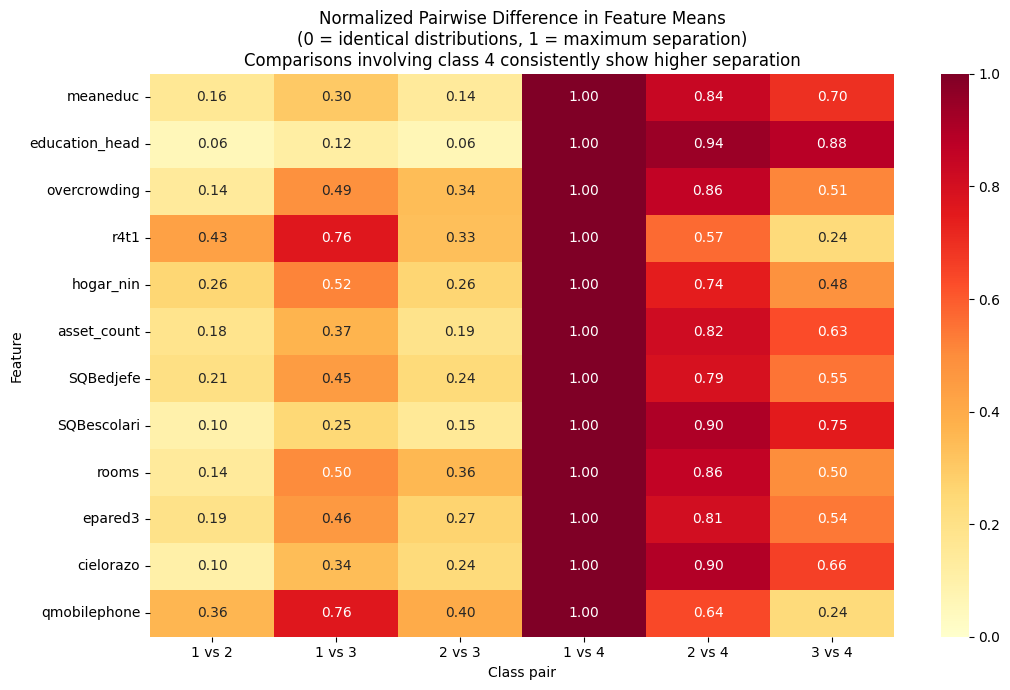

In [86]:
# All 6 pairwise absolute differences in means
diff_df = pd.DataFrame({
    "1 vs 2": (means_by_class["Extreme Poverty (1)"] - means_by_class["Moderate Poverty (2)"]).abs(),
    "1 vs 3": (means_by_class["Extreme Poverty (1)"] - means_by_class["Vulnerable (3)"]).abs(),
    "2 vs 3": (means_by_class["Moderate Poverty (2)"] - means_by_class["Vulnerable (3)"]).abs(),
    "1 vs 4": (means_by_class["Extreme Poverty (1)"] - means_by_class["Non-Poor (4)"]).abs(),
    "2 vs 4": (means_by_class["Moderate Poverty (2)"] - means_by_class["Non-Poor (4)"]).abs(),
    "3 vs 4": (means_by_class["Vulnerable (3)"]       - means_by_class["Non-Poor (4)"]).abs(),
})

# Normalize row-wise so each feature's differences are on the same 0–1 scale
diff_normalized = diff_df.div(diff_df.max(axis=1).replace(0, 1), axis=0)

plt.figure(figsize=(11, 7))
sns.heatmap(diff_normalized, annot=True, fmt=".2f", cmap="YlOrRd",
            vmin=0, vmax=1)
plt.title(
    "Normalized Pairwise Difference in Feature Means\n"
    "(0 = identical distributions, 1 = maximum separation)\n"
    "Comparisons involving class 4 consistently show higher separation"
)
plt.xlabel("Class pair")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

The heatmap reveals a clear structural pattern: across all 12 top features, comparisons
involving class 4 (non-poor) consistently show high separation values (0.51–1.00), while
comparisons between classes 1, 2, and 3 remain systematically low (0.01–0.76). The poverty
classes are not simply harder to separate, their feature distributions are near-identical
relative to the gap that exists between poor and non-poor households.

Best multiclass model: Logistic Regression
Total errors:          835
Adjacent-class errors (|true - pred| = 1): 551  (66.0%)
Non-adjacent errors   (|true - pred| > 1): 284 (34.0%)


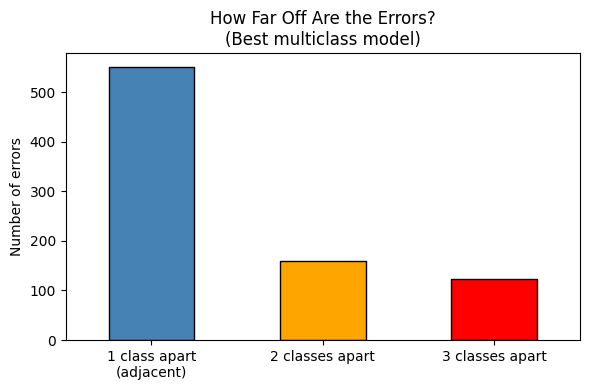

In [87]:
best_flat_preds = baseline_results[summary_baseline.iloc[0]["Model"]]["preds"]

err_mask     = y_test != best_flat_preds
true_err     = y_test[err_mask].values
pred_err     = best_flat_preds[err_mask]
gap          = np.abs(true_err - pred_err)

adjacent     = np.sum(gap == 1)
non_adjacent = np.sum(gap >  1)
total_errors = len(true_err)

print(f"Best multiclass model: {summary_baseline.iloc[0]['Model']}")
print(f"Total errors:          {total_errors}")
print(f"Adjacent-class errors (|true - pred| = 1): {adjacent}  ({100*adjacent/total_errors:.1f}%)")
print(f"Non-adjacent errors   (|true - pred| > 1): {non_adjacent} ({100*non_adjacent/total_errors:.1f}%)")

# Visualise the distribution of error gaps
plt.figure(figsize=(6, 4))
pd.Series(gap).value_counts().sort_index().plot(
    kind="bar", color=["steelblue","orange","red"], edgecolor="black"
)
plt.xticks([0, 1, 2], ["1 class apart\n(adjacent)", "2 classes apart", "3 classes apart"], rotation=0)
plt.title("How Far Off Are the Errors?\n(Best multiclass model)")
plt.ylabel("Number of errors")
plt.tight_layout()
plt.show()


When the best multiclass model makes an error, it almost always confuses a household with
its immediate neighbour on the poverty scale. This rules out random guessing, the model
correctly understands poverty as a spectrum. The problem is that the feature-space boundaries
between adjacent poverty levels are too diffuse to reliably cross.

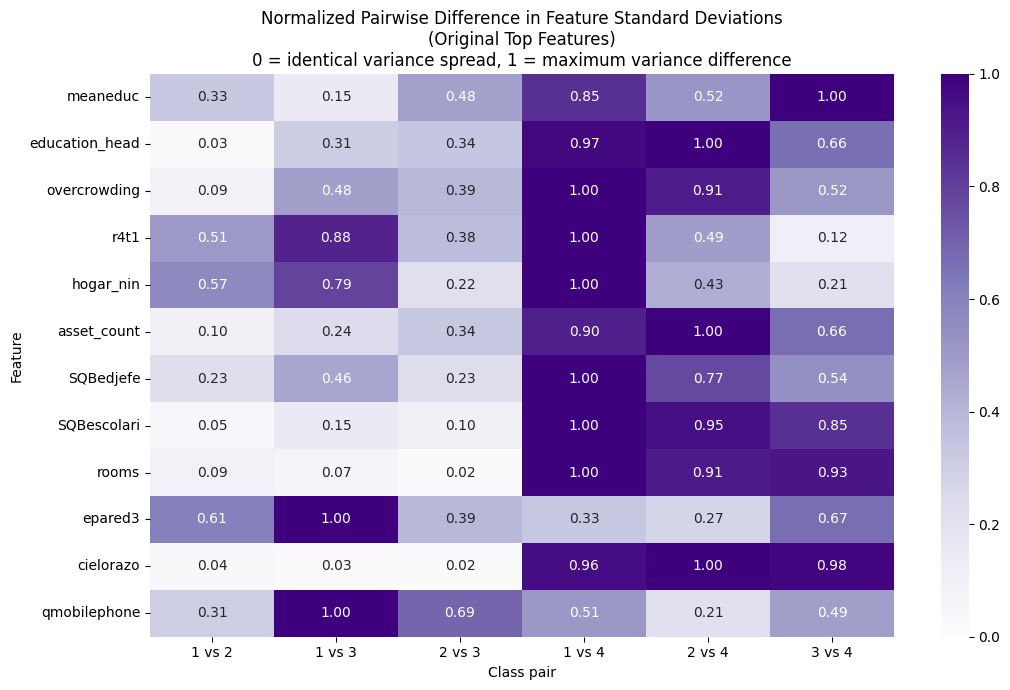

In [88]:
# Calculate standard deviations by class
stds_by_class = X_analysis.groupby("Target")[top_features_analysis].std().T
stds_by_class.columns = ["Extreme Poverty (1)", "Moderate Poverty (2)", "Vulnerable (3)", "Non-Poor (4)"]

# All 6 pairwise absolute differences in standard deviations
diff_std_df = pd.DataFrame({
    "1 vs 2": (stds_by_class["Extreme Poverty (1)"] - stds_by_class["Moderate Poverty (2)"]).abs(),
    "1 vs 3": (stds_by_class["Extreme Poverty (1)"] - stds_by_class["Vulnerable (3)"]).abs(),
    "2 vs 3": (stds_by_class["Moderate Poverty (2)"] - stds_by_class["Vulnerable (3)"]).abs(),
    "1 vs 4": (stds_by_class["Extreme Poverty (1)"] - stds_by_class["Non-Poor (4)"]).abs(),
    "2 vs 4": (stds_by_class["Moderate Poverty (2)"] - stds_by_class["Non-Poor (4)"]).abs(),
    "3 vs 4": (stds_by_class["Vulnerable (3)"]       - stds_by_class["Non-Poor (4)"]).abs(),
})

# Normalize row-wise so each feature's differences are on the same 0–1 scale
diff_std_normalized = diff_std_df.div(diff_std_df.max(axis=1).replace(0, 1), axis=0)

plt.figure(figsize=(11, 7))
sns.heatmap(diff_std_normalized, annot=True, fmt=".2f", cmap="Purples", vmin=0, vmax=1)
plt.title(
    "Normalized Pairwise Difference in Feature Standard Deviations\n"
    "(Original Top Features)\n"
    "0 = identical variance spread, 1 = maximum variance difference"
)
plt.xlabel("Class pair")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

The standard deviation heatmap confirms that the structural overlap among poverty levels extends beyond feature means to their overall dispersion, as classes 1, 2, and 3 exhibit near-identical variance spreads compared to the sharp distinctions seen in the non-poor population (Class 4).

## Re-selecting features
As a final test, features were re-selected using only poor households (classes 1–3), giving
the model every possible advantage.

In [90]:
# Re-select features using only poor households (classes 1–3)

mask_poor_train = y_train.isin([1, 2, 3])
X_train_poor = X_train_fs[mask_poor_train]
y_train_poor = y_train[mask_poor_train]

# Mutual Information
mi_poor = mutual_info_classif(X_train_poor, y_train_poor, random_state=42)
mi_poor_df = pd.DataFrame({"feature": X_train_poor.columns, "mi": mi_poor})

# Absolute Correlation
corr_poor = X_train_poor.corrwith(y_train_poor).abs()
corr_poor_df = pd.DataFrame({"feature": X_train_poor.columns, "corr": corr_poor})

# Combined rank
combined_poor = mi_poor_df.merge(corr_poor_df, on="feature")
combined_poor["avg_rank"] = (
    combined_poor["mi"].rank(ascending=False) +
    combined_poor["corr"].rank(ascending=False)
) / 2
combined_poor = combined_poor.sort_values("avg_rank")

top_features_poor = combined_poor.head(12)["feature"].tolist()
print("Top 12 features selected specifically to distinguish classes 1–3:")
print(top_features_poor)

Top 12 features selected specifically to distinguish classes 1–3:
['r4t1', 'edjefa', 'r4t2', 'r4h2', 'edjefe', 'meaneduc', 'SQBhogar_nin', 'hogar_adul', 'rooms', 'SQBovercrowding', 'SQBedjefe', 'hogar_nin']


/Users/mireiacalvinosaez/anaconda3/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/mireiacalvinosaez/anaconda3/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [91]:
# Compute means by class using the poor-specific top features
# We include class 4 to show how much more separated it is by comparison

X_analysis_poor = X_train_fs[top_features_poor].copy()
X_analysis_poor["Target"] = y_train.values

means_by_class_poor = X_analysis_poor.groupby("Target")[top_features_poor].mean().T
means_by_class_poor.columns = ["Extreme Poverty (1)", "Moderate Poverty (2)", "Vulnerable (3)", "Non-Poor (4)"]

print("Feature means by poverty class — features selected to best separate classes 1–3:")
print(means_by_class_poor.round(3).to_string())

Feature means by poverty class — features selected to best separate classes 1–3:
                 Extreme Poverty (1)  Moderate Poverty (2)  Vulnerable (3)  Non-Poor (4)
r4t1                           1.667                 1.193           0.827         0.569
edjefa                         3.533                 2.581           1.680         3.176
r4t2                           2.781                 3.181           3.549         3.210
r4h2                           1.062                 1.464           1.780         1.587
edjefe                         2.207                 3.381           4.487         6.016
meaneduc                       6.707                 7.284           7.799        10.320
SQBhogar_nin                   9.679                 6.389           4.563         2.377
hogar_adul                     2.085                 2.342           2.674         2.699
rooms                          4.351                 4.476           4.785         5.217
SQBovercrowding              

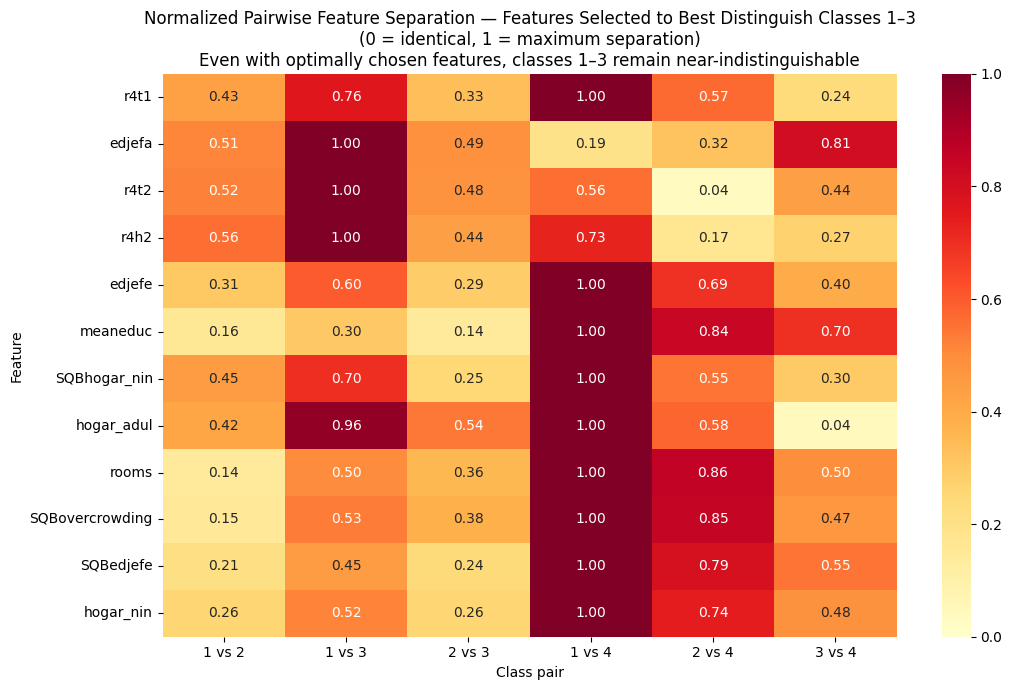

In [92]:
# Pairwise normalized differences, using features hand-picked for classes 1–3

diff_poor = pd.DataFrame({
    "1 vs 2": (means_by_class_poor["Extreme Poverty (1)"] - means_by_class_poor["Moderate Poverty (2)"]).abs(),
    "1 vs 3": (means_by_class_poor["Extreme Poverty (1)"] - means_by_class_poor["Vulnerable (3)"]).abs(),
    "2 vs 3": (means_by_class_poor["Moderate Poverty (2)"] - means_by_class_poor["Vulnerable (3)"]).abs(),
    "1 vs 4": (means_by_class_poor["Extreme Poverty (1)"] - means_by_class_poor["Non-Poor (4)"]).abs(),
    "2 vs 4": (means_by_class_poor["Moderate Poverty (2)"] - means_by_class_poor["Non-Poor (4)"]).abs(),
    "3 vs 4": (means_by_class_poor["Vulnerable (3)"]       - means_by_class_poor["Non-Poor (4)"]).abs(),
})

diff_poor_normalized = diff_poor.div(diff_poor.max(axis=1).replace(0, 1), axis=0)

plt.figure(figsize=(11, 7))
sns.heatmap(diff_poor_normalized, annot=True, fmt=".2f", cmap="YlOrRd", vmin=0, vmax=1)
plt.title(
    "Normalized Pairwise Feature Separation — Features Selected to Best Distinguish Classes 1–3\n"
    "(0 = identical, 1 = maximum separation)\n"
    "Even with optimally chosen features, classes 1–3 remain near-indistinguishable"
)
plt.xlabel("Class pair")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

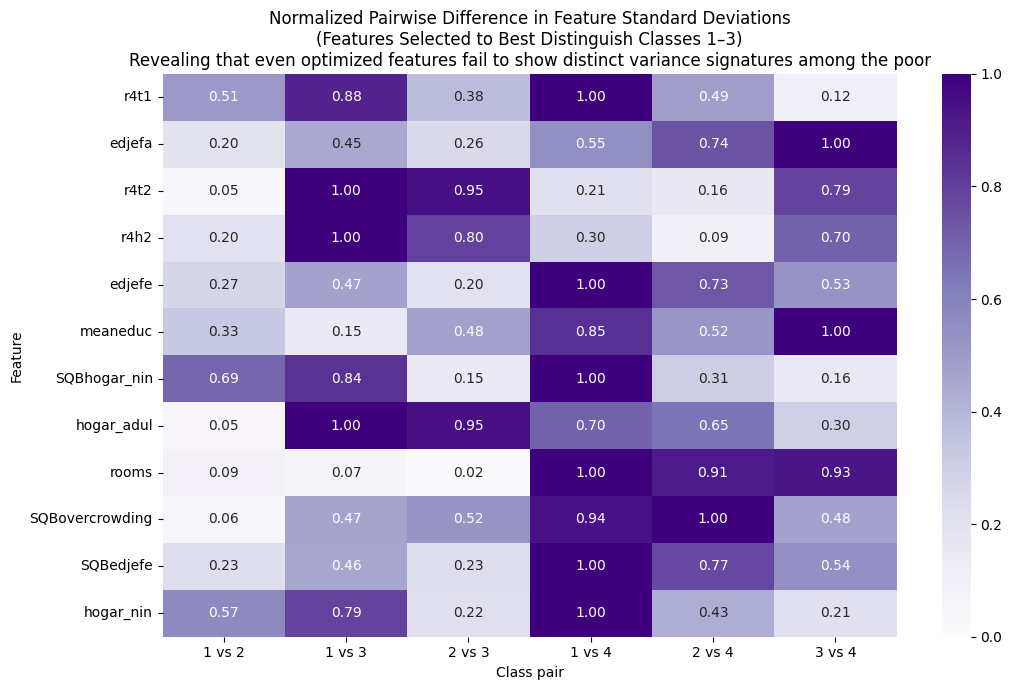

In [93]:
# Calculate standard deviations by class using poor-specific features
stds_by_class_poor = X_analysis_poor.groupby("Target")[top_features_poor].std().T
stds_by_class_poor.columns = ["Extreme Poverty (1)", "Moderate Poverty (2)", "Vulnerable (3)", "Non-Poor (4)"]

# Pairwise normalized differences in stds
diff_std_poor = pd.DataFrame({
    "1 vs 2": (stds_by_class_poor["Extreme Poverty (1)"] - stds_by_class_poor["Moderate Poverty (2)"]).abs(),
    "1 vs 3": (stds_by_class_poor["Extreme Poverty (1)"] - stds_by_class_poor["Vulnerable (3)"]).abs(),
    "2 vs 3": (stds_by_class_poor["Moderate Poverty (2)"] - stds_by_class_poor["Vulnerable (3)"]).abs(),
    "1 vs 4": (stds_by_class_poor["Extreme Poverty (1)"] - stds_by_class_poor["Non-Poor (4)"]).abs(),
    "2 vs 4": (stds_by_class_poor["Moderate Poverty (2)"] - stds_by_class_poor["Non-Poor (4)"]).abs(),
    "3 vs 4": (stds_by_class_poor["Vulnerable (3)"]       - stds_by_class_poor["Non-Poor (4)"]).abs(),
})

# Normalize row-wise
diff_std_poor_normalized = diff_std_poor.div(diff_std_poor.max(axis=1).replace(0, 1), axis=0)

plt.figure(figsize=(11, 7))
sns.heatmap(diff_std_poor_normalized, annot=True, fmt=".2f", cmap="Purples", vmin=0, vmax=1)
plt.title(
    "Normalized Pairwise Difference in Feature Standard Deviations\n"
    "(Features Selected to Best Distinguish Classes 1–3)\n"
    "Revealing that even optimized features fail to show distinct variance signatures among the poor"
)
plt.xlabel("Class pair")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

While Class 1 vs. 3 naturally exhibits a higher degree of separation as they are two ordinal steps apart, the boundaries between the three poverty levels remain critically blurred, even when utilizing a feature set specifically optimized to maximize these distinctions.

## Conclusion on Multiclass Classification

The distributional analysis reveals a structural data problem: classes 1, 2, and 3 have very similar feature means, making them nearly indistinguishable with the available features. Adjacent-class errors dominate, so the model correctly understands the poverty spectrum but cannot reliably draw specified boundaries between severity levels.

This is not a modelling failure. Class weighting and SMOTE address *sampling* imbalance, not *feature overlap*. No standard supervised learning approach can reliably separate classes whose feature distributions are near-identical.

**We therefore reframe the problem**: rather than predicting exact poverty severity, we ask whether a household is *poor at all* (classes 1–3) versus *non-poor* (class 4). This binary distinction has clear operational value and, critically, is one the data can actually support.

In [94]:
#  Binary classification: Poor (1-3) vs Non-Poor (4)
y_train_binary = (y_train != 4).astype(int)   # 0 = non-poor, 1 = poor
y_test_binary  = (y_test  != 4).astype(int)

print("Binary class distribution (train):")
print(pd.Series(y_train_binary).value_counts().rename({0:"Non-Poor (4)", 1:"Poor (1-3)"}))

cv5_bin = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
binary_results = {}

# Logistic Regression
scaler_bin = StandardScaler()
X_tr_bin_sc = scaler_bin.fit_transform(X_train_selected)
X_te_bin_sc = scaler_bin.transform(X_test_selected)

grid_bin_lr = GridSearchCV(
    LogisticRegression(max_iter=5000, random_state=42),
    param_grid={"C": [0.01, 0.1, 1, 10], "class_weight": ["balanced", {0:3,1:1}]},
    cv=cv5_bin, scoring="f1", n_jobs=-1, refit=True,
)
grid_bin_lr.fit(X_tr_bin_sc, y_train_binary)
binary_results["Logistic Regression"] = grid_bin_lr.predict(X_te_bin_sc)

# Random Forest
grid_bin_rf = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid={
        "n_estimators":     [200, 400],
        "max_depth":        [5, 10, None],
        "min_samples_leaf": [1, 2, 5],
        "class_weight":     ["balanced", {0:3,1:1}],
    },
    cv=cv5_bin, scoring="f1", n_jobs=-1, refit=True,
)
grid_bin_rf.fit(X_train_selected, y_train_binary)
binary_results["Random Forest"] = grid_bin_rf.predict(X_test_selected)

# AdaBoost
grid_bin_ada = GridSearchCV(
    AdaBoostClassifier(
        estimator=DecisionTreeClassifier(class_weight="balanced"),
        random_state=42,
    ),
    param_grid={
        "n_estimators":         [100, 200, 400],
        "learning_rate":        [0.5, 1.0, 1.5],
        "estimator__max_depth": [1, 2, 3],
    },
    cv=cv5_bin, scoring="f1", n_jobs=-1, refit=True,
)
grid_bin_ada.fit(X_train_selected, y_train_binary)
binary_results["AdaBoost"] = grid_bin_ada.predict(X_test_selected)

# KNN
scaler_bin_knn = StandardScaler()
X_tr_bin_knn = scaler_bin_knn.fit_transform(X_train_selected)
X_te_bin_knn = scaler_bin_knn.transform(X_test_selected)

grid_bin_knn = GridSearchCV(
    KNeighborsClassifier(),
    param_grid={
        "n_neighbors": [3, 5, 9, 15, 21],
        "weights":     ["uniform", "distance"],
        "metric":      ["euclidean", "manhattan"],
    },
    cv=cv5_bin, scoring="f1", n_jobs=-1, refit=True,
)
grid_bin_knn.fit(X_tr_bin_knn, y_train_binary)
binary_results["KNN"] = grid_bin_knn.predict(X_te_bin_knn)

Binary class distribution (train):
Target
Non-Poor (4)    4795
Poor (1-3)      2832
Name: count, dtype: int64


In [101]:
# Summary
summary_binary = pd.DataFrame([
    {
        "Model":    name,
        "F1": round(f1_score(y_test_binary, preds), 4),
        "Accuracy": round(accuracy_score(y_test_binary, preds), 4),
        "Recall":    round(classification_report(y_test_binary, preds, output_dict=True)["1"]["recall"], 4),
        'Precision': round(classification_report(y_test_binary, preds, output_dict=True)["1"]["precision"], 4)
    }
    for name, preds in binary_results.items()
]).sort_values("F1", ascending=False).reset_index(drop=True)

print(summary_binary.to_string(index=False))

              Model     F1  Accuracy  Recall  Precision
Logistic Regression 0.6805    0.7415  0.7489     0.6235
      Random Forest 0.6503    0.7614  0.6034     0.7050
           AdaBoost 0.6398    0.7095  0.7019     0.5878
                KNN 0.5159    0.6644  0.4864     0.5491


In [96]:
# Classification report for best binary model
best_bin_name  = summary_binary.iloc[0]["Model"]
best_bin_preds = binary_results[best_bin_name]
print(f"\nClassification Report — {best_bin_name} (best binary model):")
print(classification_report(y_test_binary, best_bin_preds, target_names=["Non-Poor (4)", "Poor (1-3)"]))


Classification Report — Logistic Regression (best binary model):
              precision    recall  f1-score   support

Non-Poor (4)       0.83      0.74      0.78      1206
  Poor (1-3)       0.62      0.75      0.68       701

    accuracy                           0.74      1907
   macro avg       0.73      0.74      0.73      1907
weighted avg       0.76      0.74      0.75      1907



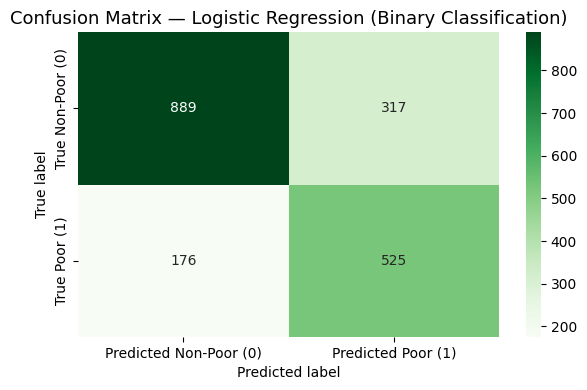

In [97]:
# Confusion matrix for best binary model

cm_bin = confusion_matrix(y_test_binary, best_bin_preds)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_bin, annot=True, fmt="d", cmap="Greens",
            xticklabels=["Predicted Non-Poor (0)", "Predicted Poor (1)"],
            yticklabels=["True Non-Poor (0)", "True Poor (1)"])
plt.title(f"Confusion Matrix — {best_bin_name} (Binary Classification)", fontsize=13)
plt.ylabel("True label")
plt.xlabel("Predicted label")
plt.tight_layout()
plt.show()

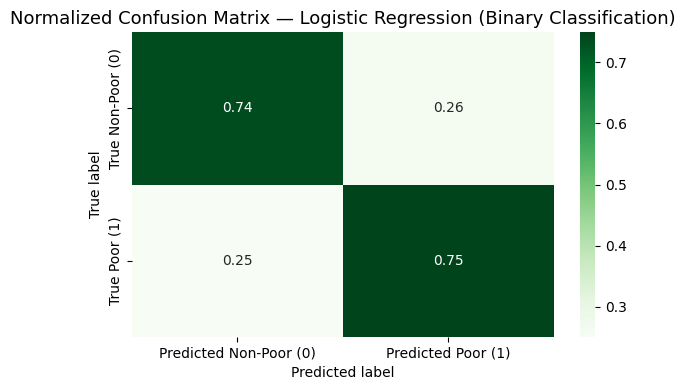

In [98]:
# Normalized confusion matrix for best binary model
cm_bin_norm = cm_bin.astype('float') / cm_bin.sum(axis=1)[:, np.newaxis]
plt.figure(figsize=(6, 4))
sns.heatmap(cm_bin_norm, annot=True, fmt=".2f", cmap="Greens",
            xticklabels=["Predicted Non-Poor (0)", "Predicted Poor (1)"],
            yticklabels=["True Non-Poor (0)", "True Poor (1)"])
plt.title(f"Normalized Confusion Matrix — {best_bin_name} (Binary Classification)", fontsize=13)
plt.ylabel("True label")
plt.xlabel("Predicted label")
plt.tight_layout()
plt.show()

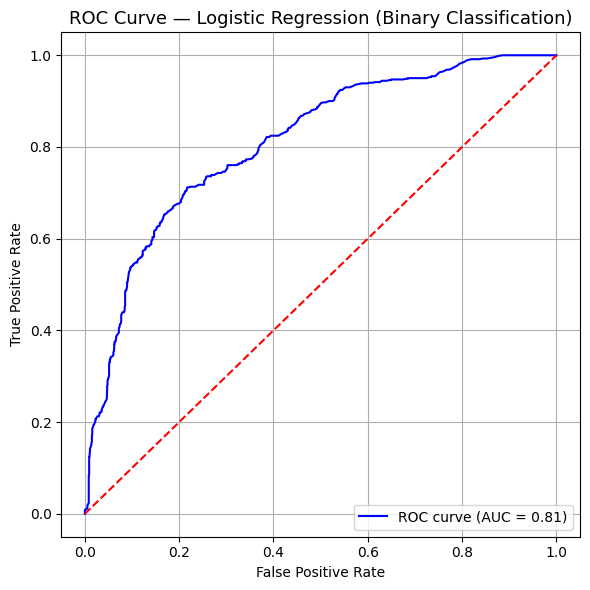

In [99]:
#ROC curve for RF
best_bin_model = grid_bin_rf
y_prob = best_bin_model.predict_proba(X_test_selected)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test_binary, y_prob)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, color='blue', label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.title(f"ROC Curve — {best_bin_name} (Binary Classification)", fontsize=13)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid()
plt.tight_layout()
plt.show()
